::: {.content-hidden}

## Info de las webcams

Algunos comandos útiles para trastear con las webcams.
:::

In [1]:
#| include: false

!cyme --filter-name "webcam"

  1   5 󰍽 0x046d 0x0825 C270 HD WEBCAM     200901010001       usb    480.0 Mb/s
  3   2  0x32ac 0x001c Laptop Webcam M... FRANJBCHA15015012D usb    480.0 Mb/s


In [2]:
#| include: false

!v4l2-ctl --list-devices

C270 HD WEBCAM (usb-0000:c1:00.3-1):
	/dev/video2
	/dev/video3
	/dev/media1

Laptop Webcam Module (2nd Gen): (usb-0000:c1:00.4-1):
	/dev/video0
	/dev/video1
	/dev/media0


In [3]:
#| include: false

!v4l2-ctl --all -d /dev/video2

Driver Info:
	Driver name      : uvcvideo
	Card type        : C270 HD WEBCAM
	Bus info         : usb-0000:c1:00.3-1
	Driver version   : 7.2.3
	Capabilities     : 0x84a00001
		Video Capture
		Metadata Capture
		Streaming
		Extended Pix Format
		Device Capabilities
	Device Caps      : 0x04200001
		Video Capture
		Streaming
		Extended Pix Format
Media Driver Info:
	Driver name      : uvcvideo
	Model            : C270 HD WEBCAM
	Serial           : 200901010001
	Bus info         : usb-0000:c1:00.3-1
	Media version    : 7.2.3
	Hardware revision: 0x00000021 (33)
	Driver version   : 7.2.3
Interface Info:
	ID               : 0x03000002
	Type             : V4L Video
Entity Info:
	ID               : 0x00000001 (1)
	Name             : C270 HD WEBCAM
	Function         : V4L2 I/O
	Flags            : default
	Pad 0x01000007   : 0: Sink
	  Link 0x02000016: from remote pad 0x100000a of entity 'Extension 8' (Video Pixel Formatter): Data, Enabled, Immutable
Priority: 2
Video input : 0 (Camera 1: ok)
Form

## Ejercicio 3.1

In [4]:
#| include: false
%load_ext autoreload
%autoreload 2

In [5]:
#| include: false
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

from miia_pec1.plot import plot_image
import miia_pec1.utils as utils
from miia_pec1.calibrate import get_corner_locations, draw, draw_cube

plt.rcParams['figure.figsize'] = (6, 4.5)
plt.rcParams['figure.dpi'] = 100

In [16]:
#| include: false
ROOT_DIR = Path.cwd()

CALIB_DIR = ROOT_DIR / 'out' / 'calibracion'
OUTPUT_DIR = ROOT_DIR / 'out' / 'calibracion'
OUTPUT_FILE = 'calibration_result.npz'
PATTERN_SIZE = (9, 6)

In [14]:
#| include: false
# Este comando captura las imagenes de la cámara, permite previsualizar el patrón sobre el tablero
!uv run miia-pec1 capture \
    --device 2 \
    --rows {PATTERN_SIZE[0]} \
    --cols {PATTERN_SIZE[1]} \
    --output {OUTPUT_DIR}

Imagen guardada en /home/cora/Documents/uned/miia/vision/tarea/pec1/out/calibracion/capture_00.jpg
Imagen guardada en /home/cora/Documents/uned/miia/vision/tarea/pec1/out/calibracion/capture_01.jpg
Imagen guardada en /home/cora/Documents/uned/miia/vision/tarea/pec1/out/calibracion/capture_02.jpg
Imagen guardada en /home/cora/Documents/uned/miia/vision/tarea/pec1/out/calibracion/capture_03.jpg
Imagen guardada en /home/cora/Documents/uned/miia/vision/tarea/pec1/out/calibracion/capture_04.jpg
Imagen guardada en /home/cora/Documents/uned/miia/vision/tarea/pec1/out/calibracion/capture_05.jpg
Imagen guardada en /home/cora/Documents/uned/miia/vision/tarea/pec1/out/calibracion/capture_06.jpg
Imagen guardada en /home/cora/Documents/uned/miia/vision/tarea/pec1/out/calibracion/capture_07.jpg
Imagen guardada en /home/cora/Documents/uned/miia/vision/tarea/pec1/out/calibracion/capture_08.jpg
Imagen guardada en /home/cora/Documents/uned/miia/vision/tarea/pec1/out/calibracion/capture_09.jpg
Imagen gua

In [28]:
#| include: false
# Comando para calibrar la cámara
!uv run miia-pec1 calibrate \
    --rows {PATTERN_SIZE[0]} \
    --cols {PATTERN_SIZE[1]} \
    --outfile {OUTPUT_DIR / OUTPUT_FILE} \
    --image-dir {CALIB_DIR}

!ls -lh {OUTPUT_DIR / OUTPUT_FILE}

-rw-r--r-- 1 cora cora 13K Nov 11 18:26 /home/cora/Documents/uned/miia/vision/tarea/pec1/out/calibracion/calibration_result.npz


Para realizar la calibración de la cámara, he utilizado un patrón de tablero de ajedrez obtenido de las [plantillas que ofrece OpenCV](https://github.com/opencv/opencv/blob/5.x/doc/pattern.png). He impreso el patrón y lo he fijado a una superficie rígida para minimizar posibles deformaciones del papel que pudiesen afectar a la calibración de la cámara.

Para la captura de la imágenes he implementado un pequeño programa CLI que puede ejecutar con el comando `uv run miia-pec1 capture`, que permite visualizar en tiempo real las esquinas detectadas para facilitar la captura del tablero en diferentes posiciones y orientaciones generando imágenes válidas para la calibración.

En @fig-calib-images se muestran las imágenes seleccionadas para el proceso de calibración.

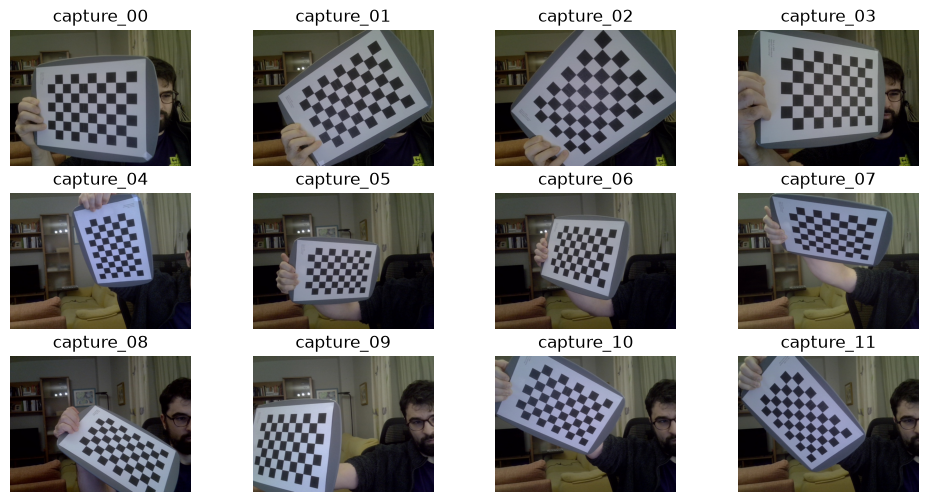

In [29]:
#| echo: false
#| label: fig-calib-images
#| fig-cap: "Imágenes del patrón de ajedrez utilizadas para la calibración"
fig, axes = plt.subplots(3, 4, figsize=(12, 6))
axes = axes.ravel()

calib_imgs = sorted(CALIB_DIR.glob('*.jpg'))

for ax, img_name in zip(axes, calib_imgs):
    img = cv.imread(img_name)
    plot_image(img, ax=ax, title=img_name.stem, convert=cv.COLOR_BGR2RGB)

Posteriormente, el comando `uv run miia-pec calibrate` realiza la calibración de la cámara a partir de las corresponcias entre los puntos del patrón y sus proyecciones en las imágenes, estima los parámetros de la cámara y los coeficientes de distorsión.

Como se observa en @fig-images-corners, el algoritmo identifica las esquinas interiores del tablero de ajedrez, que se utilizan como puntos de referencia para calcular los parámetros de calibración.

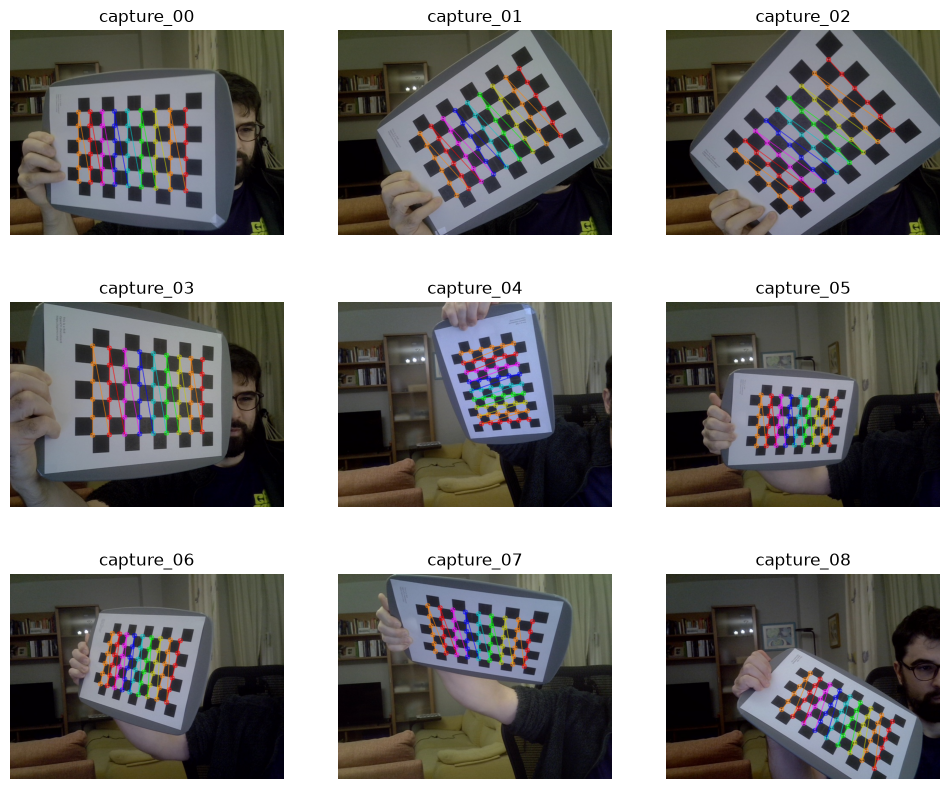

In [30]:
#| echo: false
#| label: fig-images-corners
#| fig-cap: "Detección de esquinas interiores del patrón de calibración"
fig, axes = plt.subplots(3, 3, figsize=(12, 10))
axes = axes.ravel()

results = np.load(OUTPUT_DIR / OUTPUT_FILE)
fnames = results['fnames']
corners = results['corners']
size = results['size']

for ax, img_name, corners in zip(axes, fnames, corners):
    img_name = Path(img_name)
    img = cv.imread(img_name)
    cv.drawChessboardCorners(img, size, corners, True)
    plot_image(img, ax=ax, title=img_name.stem, convert=cv.COLOR_BGR2RGB)

En @tbl-calibracion se muestran los parámetros obtenidos durante la calibración, la matriz intrínseca $\mathbf{K}$ y los coeficientes de distorsión $\mathbf{D}$.

La matriz intrínseca $\mathbf{K}$ recoge los parámetros que describen la proyección de la cámara. En particular, las distancias focales expresadas en píxeles son $f_x \approx 534.16$ y $f_y \approx 534.25$, mientras que el punto principal se encuentra en $(c_x,c_y)\approx(341.71,232.05)$.

El vector de distorsión $\mathbf{D}$ contiene los coeficientes utilizados para modelar las distorsiones radiales y tangenciales de la lente. En el modelo habitual de cinco coeficientes de OpenCV, estos se ordenan como $(k_1,k_2,p_1,p_2,k_3)$.

Estos parámetros permiten corregir la distorsión de las imágenes y realizar proyecciones geométricas más precisas.

In [31]:
#| echo: false
#| output: asis

mtx = results["mtx"]
dist = results["dist"].ravel()

# Tabla markdown para mostrar los resultados
print("| Parámetro | Valor |")
print("|:---|:---|")

# Matriz intrínseca
print(f"| Matriz intrínseca $K$ | ${utils.latex_matrix(mtx)}$ |")

# Distorsión
print(f"| Distorsión $D$ | ${utils.latex_vector(dist)}$ |")

print("\n: Resultados de la calibración de la cámara {#tbl-calibracion}\n")

| Parámetro | Valor |
|:---|:---|
| Matriz intrínseca $K$ | $\begin{bmatrix}701.7948 & 0.0000 & 316.8115 \\ 0.0000 & 702.0579 & 236.2497 \\ 0.0000 & 0.0000 & 1.0000\end{bmatrix}$ |
| Distorsión $D$ | $\left(0.0183, 0.6575, -0.0077, 0.0025, -1.8116\right)$ |

: Resultados de la calibración de la cámara {#tbl-calibracion}



### Evaluación del error de calibración

Tras completar la calibración, se analiza el error de reproyección, que mide la diferencia entres las posiciones de las esquinas detectadas y las estimadas utilizando los parámetros de calibración obtenidos.

En @fig-calibration-rms se puede observar el error de calibración para cada imagen, junto con el error de calibración global RMS.

Los resultados muestran errores relativamente reducidos, con pequeñas diferencias entre las imágenes utilizadas. El error RMS global es aproximadamente de 0,276 píxeles, lo que indica una buena correspondencia entre las observaciones y el model estimado.

::: {.callout-note}
Un RMS bajo no garantiza una calibración perfecta, es importante que las imágenes cubran diferentes orientaciones y regiones del sensor.
:::

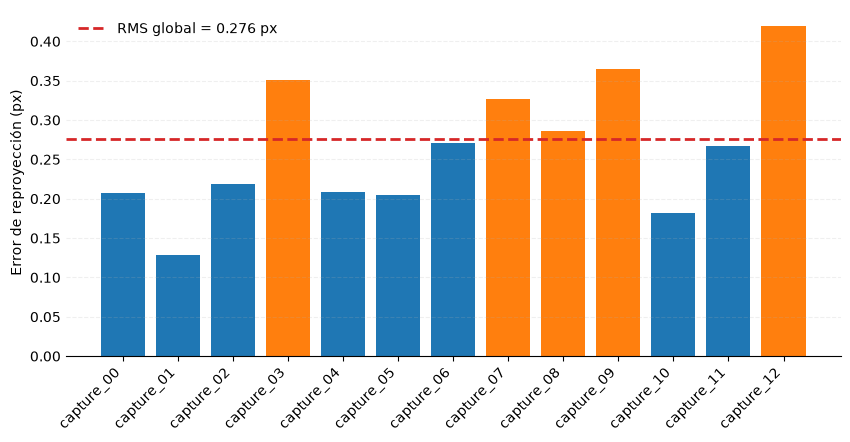

In [32]:
#| echo: false
#| label: fig-calibration-rms
#| fig-cap: "Error de reproyección por imagen y RMS global"
fig, ax = plt.subplots(1, 1, figsize=(10, 4.5))

x = np.arange(len(results["errors"]))
errors = results["errors"]
rms = results['rms']
x_labels = [Path(f).stem for f  in results["fnames"]]
colors = ['tab:blue' if e < rms else 'tab:orange' for e in errors]

ax.bar(x, errors, color=colors)
ax.axhline(rms, ls='--', lw=2, color='tab:red', label=f'RMS global = {rms.round(3)} px')

ax.set_xticks(x, labels=x_labels, rotation=45, ha='right')
ax.set_ylabel("Error de reproyección (px)")
ax.tick_params(axis="y", length=0)

ax.grid(axis='y', alpha=0.2, ls='--', zorder=0)
ax.legend(frameon=False, loc="upper left")

ax.spines[['top', 'right', 'left']].set_visible(False)


En @fig-calibration-remap-compare se compara la imagen original con su versión corregida. Aunque las diferencias son sutiles, se aprecia una ligera rectificación de las líneas y los bordes, especialmente en las zonas periféricas de la imagen.

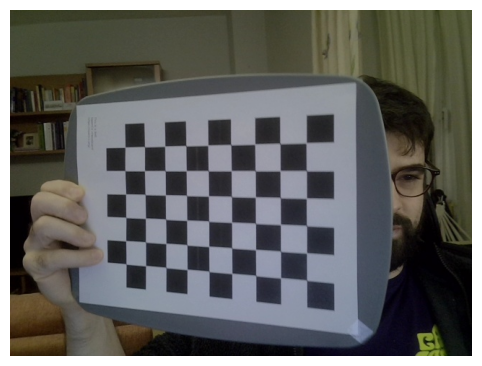

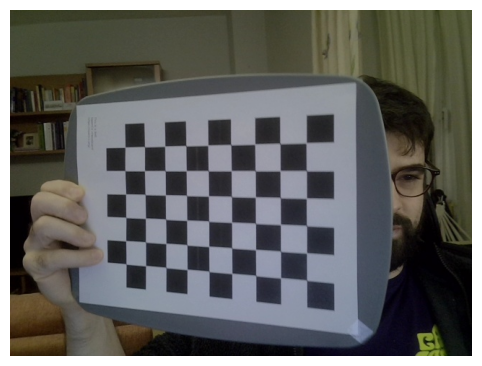

In [34]:
#| echo: false
#| label: fig-calibration-remap-compare
#| fig-cap: "Comparación de la imagen original y la imagen corregida mediante calibración"
#| fig-subcap:
#|  - "Imagen original"
#|  - "Imagen corregida"
#| layout-ncol: 2
img_orig = cv.imread(calib_imgs[0], cv.IMREAD_COLOR_RGB)
img = img_orig.copy()
h, w = img.shape[:2]

newcameramtx, roi = cv.getOptimalNewCameraMatrix(mtx, dist, (w, h), 1, (w, h))
mapx, mapy = cv.initUndistortRectifyMap(mtx, dist, None, newcameramtx, (w, h), 5)
dst = cv.remap(img, mapx, mapy, cv.INTER_LINEAR)

plot_image(img_orig)
plot_image(img)

plt.show()

## Ejercicio 3.2

¿Como podemos estimar la pose de una un objeto respecto a la cámara?

Partimos de unos puntos 3D conocidos del objeto y detectamos sus correspondientes posiciones 2D en la imagen.

In [35]:
#| include: false
# Puntos 3D de referencia

objp = np.zeros((PATTERN_SIZE[0]*PATTERN_SIZE[1], 3), np.float32)
objp[:, :2] = np.mgrid[0:PATTERN_SIZE[0],0:PATTERN_SIZE[1]].T.reshape(-1, 2)

In [44]:
#| include: false
# Puntos 2D sobre la imagen
img = cv.imread(calib_imgs[5], cv.IMREAD_COLOR_RGB)
gray = cv.cvtColor(img, cv.COLOR_RGB2GRAY)

_, corners = get_corner_locations(gray, pattern_size=PATTERN_SIZE)

In [45]:
#| echo: false
#| output: asis

# Tabla markdown para mostrar los resultados
print("| Puntos 3D conocidos | Posiciones 2D en la imagen |")
print("|:---|:---|")
for i in range(5):
    print(f"| ${utils.latex_vector(objp[i])}$ | ${utils.latex_vector(corners[i])}$ |")

print("\n: Correspondencias entre los puntos 3D del tablero y sus posiciones 2D detectadas en la imagen {#tbl-points-correspondence}\n")

| Puntos 3D conocidos | Posiciones 2D en la imagen |
|:---|:---|
| $\left(0.0000, 0.0000, 0.0000\right)$ | $\left(380.1252, 332.5765\right)$ |
| $\left(1.0000, 0.0000, 0.0000\right)$ | $\left(360.6099, 333.1312\right)$ |
| $\left(2.0000, 0.0000, 0.0000\right)$ | $\left(340.7096, 333.4769\right)$ |
| $\left(3.0000, 0.0000, 0.0000\right)$ | $\left(320.2885, 333.8613\right)$ |
| $\left(4.0000, 0.0000, 0.0000\right)$ | $\left(299.3304, 334.4000\right)$ |

: Correspondencias entre los puntos 3D del tablero y sus posiciones 2D detectadas en la imagen {#tbl-points-correspondence}



A partir de las correspondencias entre los puntos 3D y 2D, la matriz intrínseca y los coeficientes de distorsión de la cámara, `cv.solvePnP()` permite estimar la rotación y la traslación del objeto respecto a la cámara. Estos parámetros se calculan buscando que las proyecciones de los puntos 3D se ajusten lo mejor posible a los puntos 2D detectados. Esta transformación se ilustra en la @fig-image-projection.

::: {#fig-image-projection}

![](https://docs.opencv.org/5.0/_images/pinhole_homogeneous_transformation.jpg){width=85%}

Sistemas de coordenadas de la cámara y del objeto y proyección de puntos 3D en el plano de imagen. Fuente: OpenCV [@opencv-solvepnp].

:::



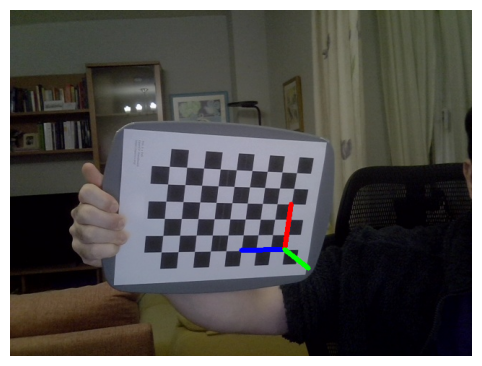

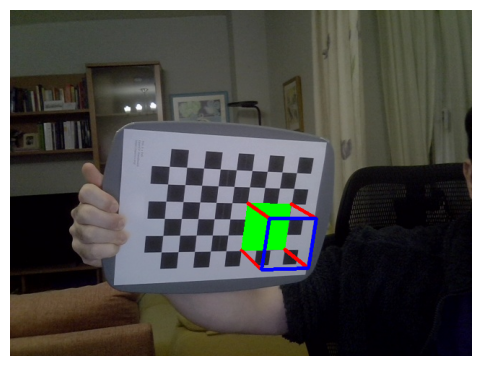

In [47]:
#| echo: false
#| label: fig-pose-estimation
#| fig-cap: "Estimación de la pos del tablero y visualización mediante elmentos virtuales 3D"
#| fig-subcap:
#|  - "Proyección de los ejes de coordenadas del tablero"
#|  - "Proyección de un cubo virtual sobre el tablero"
#| layout-ncol: 2
#| fig-pos: H
ret, rvecs, tvecs = cv.solvePnP(objp, corners, mtx, dist)

axis = np.float32([[3,0,0], [0,3,0], [0,0,-3]]).reshape(-1,3)
imgpts, jac = cv.projectPoints(axis, rvecs, tvecs, mtx, dist)
img_1 = img.copy()
draw(img_1,corners,imgpts)
plot_image(img_1)

axis = np.float32([[0,0,0], [0,3,0], [3,3,0], [3,0,0], [0,0,-3],[0,3,-3],[3,3,-3],[3,0,-3] ])
imgpts, jac = cv.projectPoints(axis, rvecs, tvecs, mtx, dist)
img_2 = img.copy()
draw_cube(img_2,corners,imgpts)
plot_image(img_2)

plt.show()

Este procedimiento podría aplicarse a la cabeza de una persona, sería necesario un modelo facial 3D de referencia junto con el sistema capaz de detectar las posiciones 2D de puntos significativos. A partir de las correspondencias, `cv.solvePnP()` permitiría estimar la orientación de la cabeza respecto a la cámara, como resume la @fig-estimated-look.

```{mermaid}
%%| label: fig-estimated-look
%%| fig-cap: "Proceso para estimar la orientación de la cabeza y la dirección de la mirada."
%%| fig-width: 6

%%{init: {"flowchart": {"nodeSpacing": 10, "rankSpacing": 15}, "themeVariables": {"fontSize": "14px"}}}%%
flowchart TD
    A["Cámara calibrada<br/>K y distorsión"]
    B["Modelo facial 3D"]
    C["Puntos faciales 2D"]
    
    D["solvePnP<br/>Estimación de R y t"]
    E["Orientación de cabeza"]

    F["Detección del iris"]
    G["Dirección ocular relativa a la cabeza"]

    H["Combinar orientación de cabeza y ojo"]
    I["Dirección estimada de la mirada"]
    
    A --> D
    B --> D
    C --> D

    D --> E
    C --> F
    F --> G

    E --> H
    G --> H
    H --> I
```

Sin embargo, la orientación de la cabeza no tiene por qué coincidir con la orientación de la mirada, ya que los ojos tienen movilidad independiente. Para estimar la mirada con mayor precisión es necesario detectar los iris y estimar la orientación de los ojos respecto a la cabeza.

Finalmente, combinando la rotación de la cabeza con la dirección ocular estimada, se podría obtener una aproximación de la dirección tridimensional de la mirada respecto a la cámara.